**Lab 5-Tasks**  
**Course: ANN** 

**Khair ul wara Hussain**
**Student Id: FA23-BAI-022**

### Lab Task 1: Loading the Dataset

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow info logs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Wine Quality data set (UCI Machine Learning Repository) - red wine, 1599 samples
# (a mirror of the UCI file is used so that it downloads directly with pandas)
RED_URL = "https://raw.githubusercontent.com/dsrscientist/DSData/master/winequality-red.csv"
red = pd.read_csv(RED_URL)

print("Dataset shape:", red.shape)
print("Number of features:", red.shape[1] - 1)
print("Missing values:", int(red.isnull().sum().sum()))
print("Duplicate rows:", int(red.duplicated().sum()))
print()
print(red['quality'].value_counts().sort_index())

Dataset shape: (1599, 12)
Number of features: 11
Missing values: 0
Duplicate rows: 240

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [2]:
red.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


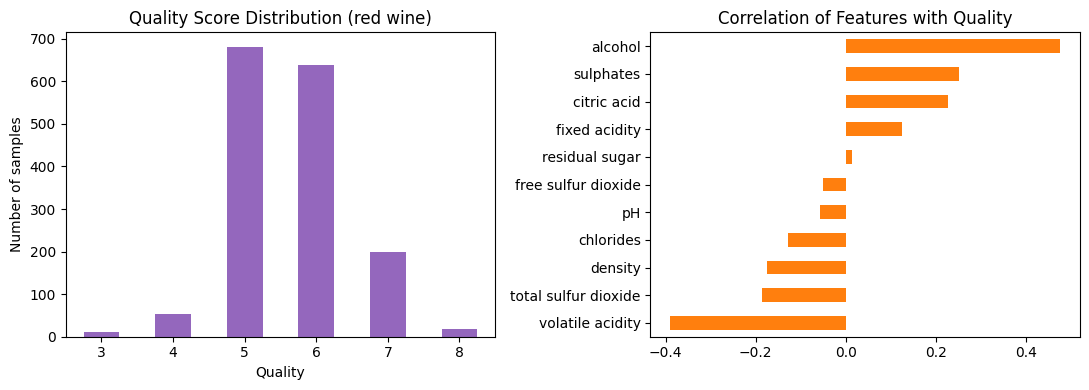

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
red['quality'].value_counts().sort_index().plot(kind='bar', color='tab:purple', ax=ax[0])
ax[0].set_title('Quality Score Distribution (red wine)')
ax[0].set_xlabel('Quality')
ax[0].set_ylabel('Number of samples')
ax[0].tick_params(axis='x', rotation=0)

corr = red.corr()['quality'].drop('quality').sort_values()
corr.plot(kind='barh', color='tab:orange', ax=ax[1])
ax[1].set_title('Correlation of Features with Quality')
plt.tight_layout()
plt.show()

### Lab Task 2: Data Preprocessing

In [4]:
# Remove duplicate rows (the same wine measured more than once would leak between train and test)
red = red.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", red.shape)

X = red.drop(columns='quality').values
y = red['quality'].values.astype('float32')

# 70% train / 15% validation / 15% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED)

# Neural networks train better when every feature is on a similar scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit only on training data (no leakage)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)
print("Train mean (first 3 features):", X_train.mean(axis=0)[:3].round(4))
print("Train std (first 3 features):", X_train.std(axis=0)[:3].round(4))

Shape after removing duplicates: (1359, 12)
Training set: (951, 11)
Validation set: (204, 11)
Test set: (204, 11)
Train mean (first 3 features): [-0.  0. -0.]
Train std (first 3 features): [1. 1. 1.]


### Lab Task 3: Building the Neural Network

In [5]:
# Quality is a score, so this is treated as a regression problem (one output neuron, no activation)
def build_model(n_features, hidden=(64, 32), optimizer='adam'):
    model = keras.Sequential()
    model.add(keras.Input(shape=(n_features,)))
    for units in hidden:
        model.add(layers.Dense(units, activation='relu'))   # ReLU hidden layers
    model.add(layers.Dense(1))                              # linear output for regression
    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
    return model

model = build_model(X_train.shape[1], hidden=(64, 32), optimizer='adam')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

### Lab Task 4: Training the Model

Training stopped after 69 epochs
Training loss at last epoch (MSE):   0.3067
Validation loss at last epoch (MSE): 0.4684
Lowest validation loss at epoch: 54 -> 0.4659


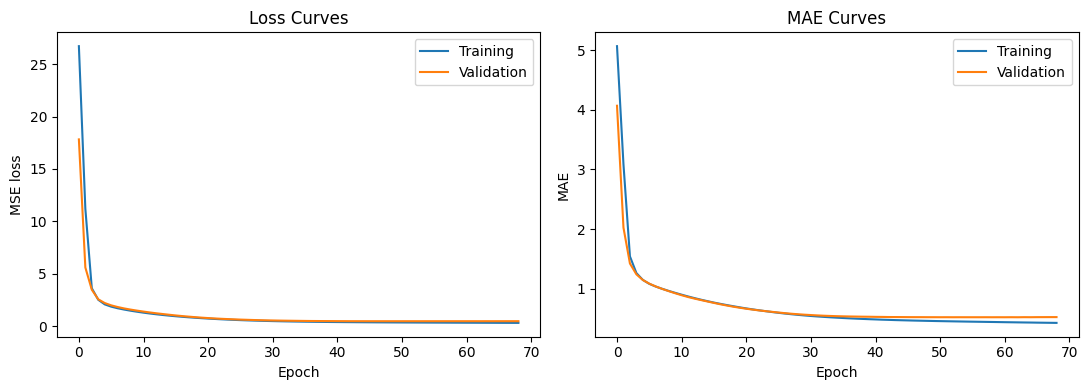

In [6]:
tf.keras.utils.set_random_seed(SEED)
model = build_model(X_train.shape[1], hidden=(64, 32), optimizer='adam')

# Early stopping: stop when validation loss has not improved for 15 epochs and keep the best weights
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=200, batch_size=32, callbacks=[early_stop], verbose=0)
print("Training stopped after", len(history.history['loss']), "epochs")

print("Training loss at last epoch (MSE):  ", round(history.history['loss'][-1], 4))
print("Validation loss at last epoch (MSE):", round(history.history['val_loss'][-1], 4))
best_ep = int(np.argmin(history.history['val_loss'])) + 1
print("Lowest validation loss at epoch:", best_ep, "->", round(min(history.history['val_loss']), 4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history['loss'], label='Training')
ax[0].plot(history.history['val_loss'], label='Validation')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('MSE loss'); ax[0].set_title('Loss Curves'); ax[0].legend()
ax[1].plot(history.history['mae'], label='Training')
ax[1].plot(history.history['val_mae'], label='Validation')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('MAE'); ax[1].set_title('MAE Curves'); ax[1].legend()
plt.tight_layout()
plt.show()

### Lab Task 5: Model Evaluation

In [7]:
def evaluate(model, X, y_true):
    pred = model.predict(X, verbose=0).ravel()
    return {
        'MSE': mean_squared_error(y_true, pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, pred)),
        'MAE': mean_absolute_error(y_true, pred),
        'R2': r2_score(y_true, pred),
        # share of wines where the rounded prediction equals the true quality score
        'Rounded accuracy': np.mean(np.clip(np.round(pred), 3, 8) == y_true),
        # share of wines predicted within 1 quality point
        'Within +-1': np.mean(np.abs(np.round(pred) - y_true) <= 1),
    }

test_metrics = evaluate(model, X_test, y_test)
for k, v in test_metrics.items():
    print(f"{k:<18}{v:.4f}")

# Naive baseline: always predict the average training quality
baseline_pred = np.full_like(y_test, y_train.mean())
print()
print("Baseline MAE (predict the mean):", round(mean_absolute_error(y_test, baseline_pred), 4))
print("Baseline RMSE (predict the mean):", round(np.sqrt(mean_squared_error(y_test, baseline_pred)), 4))

MSE               0.5560
RMSE              0.7457
MAE               0.5593
R2                0.1167
Rounded accuracy  0.5343
Within +-1        0.9608

Baseline MAE (predict the mean): 0.6667
Baseline RMSE (predict the mean): 0.7935


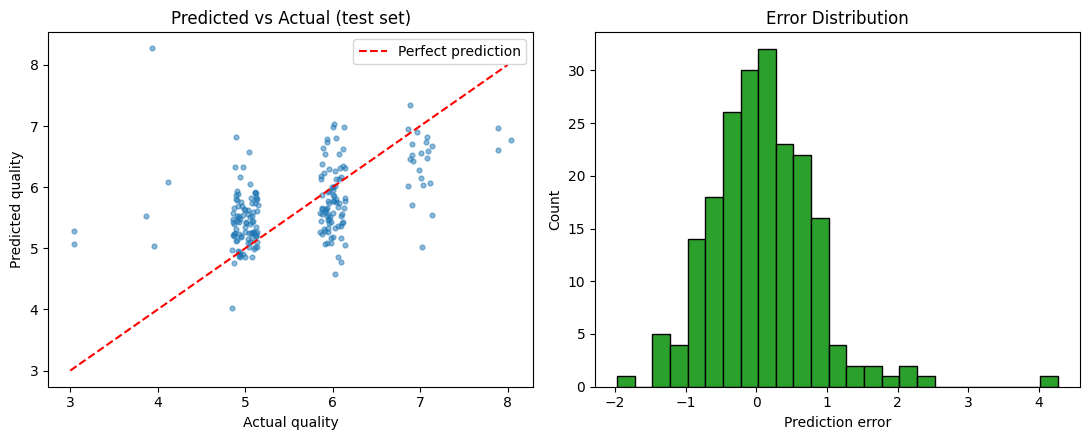

Predicted  4   5   6   7  8
Actual                     
3          0   2   0   0  0
4          0   1   2   0  1
5          1  53  36   2  0
6          0  26  46  10  0
7          0   1  10  10  0
8          0   0   0   3  0


In [8]:
pred = model.predict(X_test, verbose=0).ravel()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(y_test + np.random.uniform(-0.15, 0.15, len(y_test)), pred, s=12, alpha=0.5)
ax[0].plot([3, 8], [3, 8], 'r--', label='Perfect prediction')
ax[0].set_xlabel('Actual quality'); ax[0].set_ylabel('Predicted quality')
ax[0].set_title('Predicted vs Actual (test set)'); ax[0].legend()

ax[1].hist(pred - y_test, bins=25, color='tab:green', edgecolor='black')
ax[1].set_xlabel('Prediction error'); ax[1].set_ylabel('Count'); ax[1].set_title('Error Distribution')
plt.tight_layout()
plt.show()

# Rounded predictions vs actual classes
cm = pd.crosstab(pd.Series(y_test.astype(int), name='Actual'),
                 pd.Series(np.clip(np.round(pred), 3, 8).astype(int), name='Predicted'))
print(cm)

### Report Summary: Lab Task 1 (Building and Training a Neural Network)

**Data preprocessing**
- Dataset: Wine Quality (UCI), red wine, 1599 samples, 11 physicochemical features, target `quality` (scores 3 to 8). There were no missing values.
- 240 duplicate rows were removed (1359 left) so that the same wine cannot appear in both the training and test sets.
- Split into 70% training (951), 15% validation (204) and 15% test (204).
- StandardScaler was fitted on the training set only and applied to validation and test, because the features have very different ranges (e.g. total sulfur dioxide vs. chlorides).

**Model architecture and hyperparameters**
- Quality is a score, so the problem is treated as regression: Input(11) -> Dense(64, ReLU) -> Dense(32, ReLU) -> Dense(1, linear).
- ReLU avoids vanishing gradients; the linear output lets the network predict any score. Two hidden layers with a shrinking width (64 then 32) are enough for 11 tabular features and keep the parameter count small for ~950 training rows.
- Loss: MSE. Optimizer: Adam (learning rate 0.001). Batch size 32. Up to 200 epochs with early stopping (patience 15, best weights restored) so the number of epochs does not have to be guessed.

**Training process and evaluation metrics**
- Training stopped after 69 epochs; the lowest validation MSE (0.4659) was at epoch 54 and those weights were kept.
- Test set results: MSE 0.5560, RMSE 0.7457, MAE 0.5593, R² 0.1167. The rounded prediction matches the true quality score for 53.4% of the wines and is within one quality point for 96.1%.
- A naive model that always predicts the average quality gets MAE 0.6667 and RMSE 0.7935, so the network beats the baseline, but only modestly.

**Observations and insights**
- The training loss keeps falling while the validation loss flattens after about 50 epochs, which is the start of overfitting; early stopping handles this.
- Most wines have quality 5 or 6, so the model predicts these two classes best. The confusion table shows that extreme scores (3, 4 and 8) are almost never predicted, because there are very few examples of them.
- The low R² suggests that the 11 chemical measurements explain only part of a quality score that comes from human tasters. Regularization, tuning and more data are the next steps, which is what Lab Task 2 explores.


### Lab Task 6: Enhancement Dataset and Initial Model

In [9]:
# For the enhancement task a larger dataset is used: Wine Quality (UCI) - WHITE wine, 4898 samples
WHITE_URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/whitewines.csv"
white = pd.read_csv(WHITE_URL).drop_duplicates().reset_index(drop=True)
print("White wine shape (after removing duplicates):", white.shape)

Xw = white.drop(columns='quality').values
yw = white['quality'].values.astype('float32')

Xw_train, Xw_temp, yw_train, yw_temp = train_test_split(Xw, yw, test_size=0.30, random_state=SEED)
Xw_val, Xw_test, yw_val, yw_test = train_test_split(Xw_temp, yw_temp, test_size=0.50, random_state=SEED)

sc2 = StandardScaler()
Xw_train = sc2.fit_transform(Xw_train)
Xw_val = sc2.transform(Xw_val)
Xw_test = sc2.transform(Xw_test)
print("Train / Val / Test:", Xw_train.shape, Xw_val.shape, Xw_test.shape)

nf = Xw_train.shape[1]

def train_model(hidden=(16,), optimizer='adam', epochs=30, batch_size=32):
    """Build + train one model and return (model, history). Same seed each time for a fair comparison."""
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(nf, hidden=hidden, optimizer=optimizer)
    h = m.fit(Xw_train, yw_train, validation_data=(Xw_val, yw_val),
              epochs=epochs, batch_size=batch_size, verbose=0)
    return m, h

# Initial (baseline) model: 1 hidden layer of 16 neurons, Adam, 30 epochs, batch size 32
base_model, base_hist = train_model(hidden=(16,), optimizer='adam', epochs=30, batch_size=32)
base_val = base_hist.history['val_loss'][-1]
base_test = evaluate(base_model, Xw_test, yw_test)

print("Initial model: 1 hidden layer (16 neurons), Adam, 30 epochs, batch size 32")
print("Validation MSE:", round(base_val, 4))
for k, v in base_test.items():
    print(f"Test {k:<18}{v:.4f}")

White wine shape (after removing duplicates): (3961, 12)
Train / Val / Test: (2772, 11) (594, 11) (595, 11)


Initial model: 1 hidden layer (16 neurons), Adam, 30 epochs, batch size 32
Validation MSE: 0.6659
Test MSE               0.7711
Test RMSE              0.8781
Test MAE               0.6737
Test R2                0.0178
Test Rounded accuracy  0.4588
Test Within +-1        0.9261


### Lab Task 7: Hyperparameter Tuning (Neurons, Layers, Epochs, Batch Size)

In [10]:
# Experiment 1: number of layers and neurons (Adam, 30 epochs, batch 32)
archs = {'16': (16,), '64': (64,), '128': (128,), '64-32': (64, 32), '128-64': (128, 64), '128-64-32': (128, 64, 32)}
arch_res = {}
for name, hl in archs.items():
    _, h = train_model(hidden=hl, optimizer='adam', epochs=30, batch_size=32)
    arch_res[name] = min(h.history['val_loss'])
    print(f"Hidden layers {name:<10} best validation MSE: {arch_res[name]:.4f}")

best_arch = min(arch_res, key=arch_res.get)
print("\nBest architecture:", best_arch)

Hidden layers 16         best validation MSE: 0.6659


Hidden layers 64         best validation MSE: 0.5710


Hidden layers 128        best validation MSE: 0.5690


Hidden layers 64-32      best validation MSE: 0.5575


Hidden layers 128-64     best validation MSE: 0.5953


Hidden layers 128-64-32  best validation MSE: 0.5723

Best architecture: 64-32


In [11]:
# Experiment 2: batch size (using the best architecture)
batch_res = {}
for bs in [16, 32, 64, 128, 256]:
    _, h = train_model(hidden=archs[best_arch], optimizer='adam', epochs=30, batch_size=bs)
    batch_res[bs] = min(h.history['val_loss'])
    print(f"Batch size {bs:<4} best validation MSE: {batch_res[bs]:.4f}")

best_bs = min(batch_res, key=batch_res.get)
print("\nBest batch size:", best_bs)

Batch size 16   best validation MSE: 0.5647


Batch size 32   best validation MSE: 0.5575


Batch size 64   best validation MSE: 0.5496


Batch size 128  best validation MSE: 0.7088


Batch size 256  best validation MSE: 1.5254

Best batch size: 64


Validation MSE at epoch 10  : 1.2939
Validation MSE at epoch 30  : 0.5496
Validation MSE at epoch 50  : 0.5459
Validation MSE at epoch 100 : 0.5601
Validation MSE at epoch 150 : 0.5926

Lowest validation MSE at epoch: 51 -> 0.5456


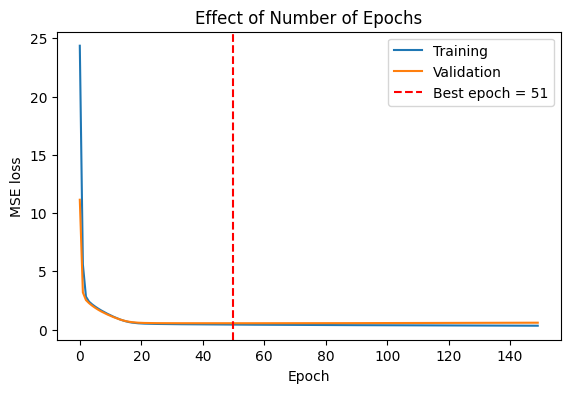

In [12]:
# Experiment 3: number of epochs - train for 150 epochs and watch where validation loss stops improving
m_ep, h_ep = train_model(hidden=archs[best_arch], optimizer='adam', epochs=150, batch_size=best_bs)
val_curve = np.array(h_ep.history['val_loss'])
best_epochs = int(np.argmin(val_curve)) + 1

for e in [10, 30, 50, 100, 150]:
    print(f"Validation MSE at epoch {e:<4}: {val_curve[e-1]:.4f}")
print("\nLowest validation MSE at epoch:", best_epochs, "->", round(val_curve.min(), 4))

plt.figure(figsize=(6.5, 4))
plt.plot(h_ep.history['loss'], label='Training')
plt.plot(val_curve, label='Validation')
plt.axvline(best_epochs - 1, color='r', linestyle='--', label=f'Best epoch = {best_epochs}')
plt.xlabel('Epoch'); plt.ylabel('MSE loss'); plt.title('Effect of Number of Epochs'); plt.legend()
plt.show()

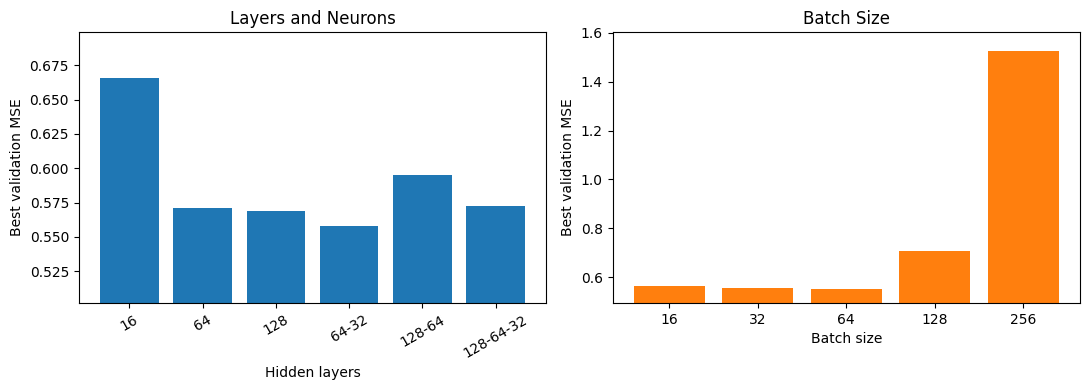

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(list(arch_res.keys()), list(arch_res.values()), color='tab:blue')
ax[0].set_ylabel('Best validation MSE'); ax[0].set_xlabel('Hidden layers'); ax[0].set_title('Layers and Neurons')
ax[0].tick_params(axis='x', rotation=30)
ax[0].set_ylim(min(arch_res.values()) * 0.9, max(arch_res.values()) * 1.05)
ax[1].bar([str(b) for b in batch_res.keys()], list(batch_res.values()), color='tab:orange')
ax[1].set_ylabel('Best validation MSE'); ax[1].set_xlabel('Batch size'); ax[1].set_title('Batch Size')
ax[1].set_ylim(min(batch_res.values()) * 0.9, max(batch_res.values()) * 1.05)
plt.tight_layout()
plt.show()

### Lab Task 8: Advanced Optimizers

SGD                    best validation MSE: 0.5449


SGD + momentum 0.9     best validation MSE: 0.5333


RMSprop                best validation MSE: 0.5733


Adam                   best validation MSE: 0.5456

Best optimizer: SGD + momentum 0.9


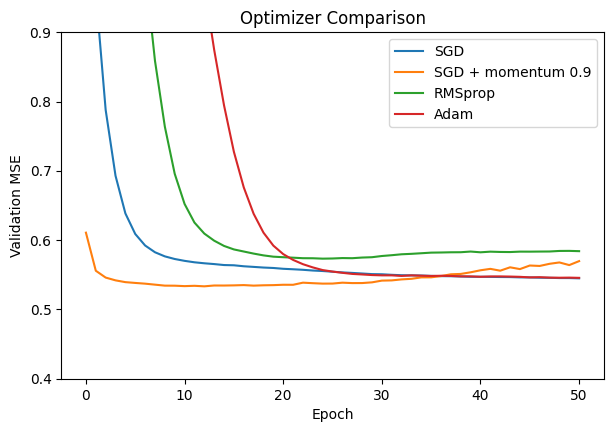

In [14]:
# Compare optimizers with the tuned architecture / batch size / epochs from Task 7
opt_factories = {
    'SGD':                lambda: keras.optimizers.SGD(learning_rate=0.01),
    'SGD + momentum 0.9': lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'RMSprop':            lambda: keras.optimizers.RMSprop(learning_rate=0.001),
    'Adam':               lambda: keras.optimizers.Adam(learning_rate=0.001),
}
opt_res, opt_hist = {}, {}
for name, make in opt_factories.items():
    _, h = train_model(hidden=archs[best_arch], optimizer=make(), epochs=best_epochs, batch_size=best_bs)
    opt_hist[name] = h.history['val_loss']
    opt_res[name] = min(h.history['val_loss'])
    print(f"{name:<22} best validation MSE: {opt_res[name]:.4f}")

best_opt = min(opt_res, key=opt_res.get)
print("\nBest optimizer:", best_opt)

plt.figure(figsize=(7, 4.5))
for name, curve in opt_hist.items():
    plt.plot(curve, label=name)
plt.xlabel('Epoch'); plt.ylabel('Validation MSE'); plt.title('Optimizer Comparison'); plt.legend()
plt.ylim(0.4, 0.9)
plt.show()

### Lab Task 9: Final Comparison

In [15]:
# Retrain with the best settings found above and evaluate once on the untouched test set
tuned_model, tuned_hist = train_model(hidden=archs[best_arch], optimizer=opt_factories[best_opt](),
                                      epochs=best_epochs, batch_size=best_bs)
tuned_test = evaluate(tuned_model, Xw_test, yw_test)

print("Best settings -> layers:", best_arch, "| batch size:", best_bs, "| epochs:", best_epochs, "| optimizer:", best_opt)
print()
cmp = pd.DataFrame({'Initial model': base_test, 'Improved model': tuned_test}).round(4)
cmp['Change'] = (cmp['Improved model'] - cmp['Initial model']).round(4)
print(cmp.to_string())

Best settings -> layers: 64-32 | batch size: 64 | epochs: 51 | optimizer: SGD + momentum 0.9

                  Initial model  Improved model  Change
MSE                      0.7711          0.5735 -0.1976
RMSE                     0.8781          0.7573 -0.1208
MAE                      0.6737          0.5866 -0.0871
R2                       0.0178          0.2695  0.2517
Rounded accuracy         0.4588          0.5294  0.0706
Within +-1               0.9261          0.9462  0.0201


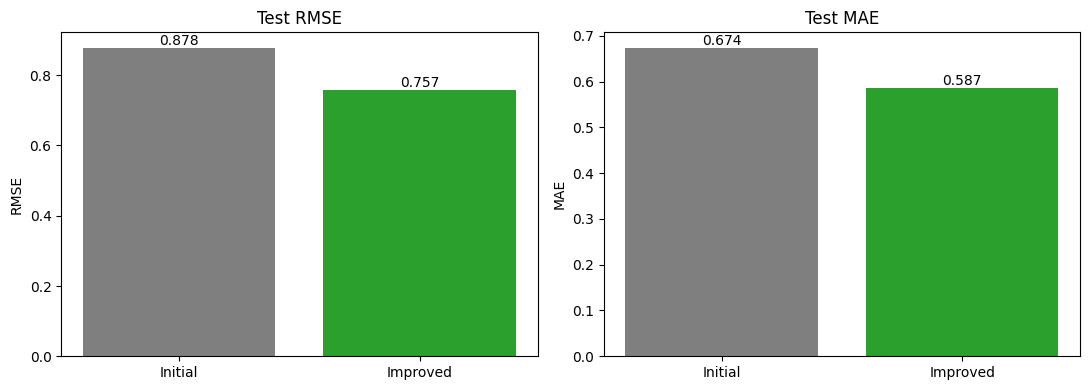

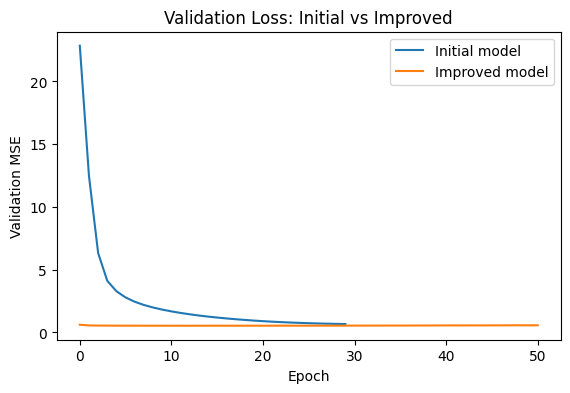

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, metric in zip(ax, ['RMSE', 'MAE']):
    a.bar(['Initial', 'Improved'], [base_test[metric], tuned_test[metric]], color=['tab:gray', 'tab:green'])
    a.set_title(f'Test {metric}'); a.set_ylabel(metric)
    for i, v in enumerate([base_test[metric], tuned_test[metric]]):
        a.text(i, v, f'{v:.3f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6.5, 4))
plt.plot(base_hist.history['val_loss'], label='Initial model')
plt.plot(tuned_hist.history['val_loss'], label='Improved model')
plt.xlabel('Epoch'); plt.ylabel('Validation MSE'); plt.title('Validation Loss: Initial vs Improved'); plt.legend()
plt.show()

### Report Summary: Lab Task 2 (Enhancing Neural Network Performance)

**Initial model performance**
- Dataset: Wine Quality (UCI), white wine, 4898 samples (3961 after removing duplicates), same preprocessing as Task 1 (70/15/15 split, StandardScaler fitted on the training set).
- Initial model: 1 hidden layer with 16 neurons, Adam, 30 epochs, batch size 32.
- Test results: MSE 0.7711, RMSE 0.8781, MAE 0.6737, R² 0.0178, rounded accuracy 45.9%. The model explains almost none of the variance.

**Techniques applied for improvement**
- Number of layers and neurons (validation MSE): 16 -> 0.6659, 64 -> 0.5710, 128 -> 0.5690, 64-32 -> 0.5575, 128-64 -> 0.5953, 128-64-32 -> 0.5723. The best was 64-32.
- Batch size: 16 -> 0.5647, 32 -> 0.5575, 64 -> 0.5496, 128 -> 0.7088, 256 -> 1.5254. The best was 64. Large batches give fewer weight updates in a fixed number of epochs, so they had not converged.
- Epochs: validation loss reached its minimum at epoch 51 (0.5456) and then slowly rose (0.5601 at epoch 100, 0.5926 at epoch 150), which shows overfitting, so 51 epochs were used.
- Optimizers (validation MSE): SGD 0.5449, SGD with momentum 0.9 0.5333, RMSprop 0.5733, Adam 0.5456. SGD with momentum was the best.

**Improved model performance**
- Final settings: hidden layers 64-32, batch size 64, 51 epochs, SGD with momentum 0.9 (learning rate 0.01).
- Test results: MSE 0.5735 (from 0.7711), RMSE 0.7573 (from 0.8781), MAE 0.5866 (from 0.6737), R² 0.2695 (from 0.0178), rounded accuracy 52.9% (from 45.9%), within +-1 quality point 94.6% (from 92.6%).

**Observations and insights**
- The biggest gain came from giving the network more capacity: moving from 16 neurons to 64-32 lowered validation MSE by about 16%. Going deeper or wider than that did not help.
- Batch size and the number of epochs matter together: too large a batch or too few epochs under-trains the model, too many epochs over-trains it.
- The optimizer differences (0.533 to 0.573) are small and come from a single run per setting, so they should not be over-interpreted. Momentum helped plain SGD, and Adam and SGD with momentum ended up close.
- Tuning was done on the validation set only, and the test set was used once at the end, so the improvement is not caused by tuning on the test data.
- Results can differ slightly between machines and TensorFlow versions even with a fixed seed.
